<a href="https://colab.research.google.com/github/marthinaf03/ml-hotel-booking-cancellation/blob/main/hotel_booking_cancellation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel Booking Cancellation Prediction

In [142]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Business Understanding

### 1.1 Problem definition

In the hotel industry, booking cancellations are a major source of lost revenue. A hotel room is a perishable product: if a room stays empty for one night, that revenue is lost forever and cannot be recovered later.

The impact of a cancellation depends on when it happens. If a guest cancels months in advance, the hotel still has time to sell the room again. If the cancellation arrives just a few days before the arrival, it is much harder to find a new guest, because most travellers book their stay well in advance.

The goal of this project is to predict whether a booking will be cancelled (`is_canceled`) using the information available at booking time, and to understand which types of bookings and customers are most at risk. The model is intended to support the hotel's revenue management and reservations team in two concrete actions:
- contacting high-risk guests before their arrival to confirm the booking;
- requiring a deposit for the bookings with the highest cancellation risk.

### 1.2 Cost of errors and choice of metrics

The model can make two types of errors:
- False negative: the model predicts that the guest will arrive, but the booking is cancelled. The hotel takes no action and the room may remain empty, causing lost revenue.
- False positive: the model predicts a cancellation, but the guest arrives. With the actions considered in this project (a reminder or a deposit request), the cost is small: an extra contact or a slightly stricter booking condition.

For this reason, false negatives are the most costly error, and Recall on the cancelled class is the main metric: we want to identify as many cancellations as possible. Since a model that flags every booking as "cancelled" would have perfect Recall but be useless, we also consider Precision, the F1-score (balance between Precision and Recall) and the PR-AUC, which is more informative than accuracy or ROC-AUC when the classes are imbalanced.

A more aggressive use of the model, such as overbooking, would make false positives much more expensive (a guest arriving without an available room). This scenario is not the main focus of the project, but it is discussed in the Deployment section.

## 2. Data Understanding

### 2.1 Data import


In [143]:
URL = "https://raw.githubusercontent.com/marthinaf03/ml-hotel-booking-cancellation/main/data/hotel_bookings.csv"
df = pd.read_csv(URL)
df.shape

(119390, 32)

### 2.2 Attribute description


In [144]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [145]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

**Observations**
- The dataset contains 119,390 bookings and 32 attributes; the target variable `is_canceled` is binary (0 = not cancelled, 1 = cancelled) and has no missing values.
- Missing values are present in four columns: `company`, `agent`, `country` and `children` (quantified below). The `NULL` strings in the original CSV are correctly read by pandas as missing values.
- `agent` and `company` are stored as numbers (`float64`), but they are **identifiers** of the travel agency and of the company that made the booking: they must be treated as categorical variables, not as numerical quantities.
- `children` is stored as `float64` only because of its missing values; it represents a count and will be converted to integer.
- Ten attributes are categorical (`object`): `hotel`, `arrival_date_month`, `meal`, `country`, `market_segment`, `distribution_channel`, `reserved_room_type`, `assigned_room_type`, `deposit_type`, `customer_type`. They will need to be encoded before modeling.
- `reservation_status` and `reservation_status_date` describe the final outcome of the booking and will be removed to avoid data leakage (see Data Preparation).

In [146]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_pct[missing > 0].sort_values(ascending=False)

,0
company,94.31
agent,13.69
country,0.41
children,0.00


`company` is missing in 94.31% of the bookings, so it carries very little information as it is; `agent` is missing in 13.69% of the rows, while `country` (0.41%) and `children` (4 rows) have only a negligible number of missing values. The handling of each case is discussed in Data Preparation.

### 2.3 Target distribution

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


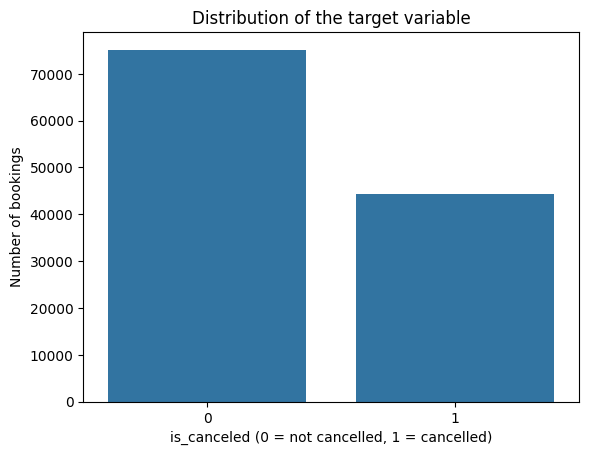

In [147]:
print(df['is_canceled'].value_counts())
print(df['is_canceled'].value_counts(normalize=True).round(4) * 100)

sns.countplot(x='is_canceled', data=df)
plt.title('Distribution of the target variable')
plt.xlabel('is_canceled (0 = not cancelled, 1 = cancelled)')
plt.ylabel('Number of bookings')
plt.show()

About 63% of the bookings were not cancelled and 37% were cancelled. The classes are **moderately imbalanced**: not as extreme as in fraud detection, but enough to make accuracy a misleading metric (a model always predicting "not cancelled" would reach 63% accuracy while detecting no cancellation). This confirms the choice of Recall, F1-score and PR-AUC made in the Business Understanding phase.

### 2.4 Exploratory analysis
The following analyses check how the cancellation rate changes across the main attributes, in order to verify the hypotheses formulated in the Business Understanding phase. The red dashed line in each plot shows the overall cancellation rate (37%).

In [148]:
def plot_cancel_rate(data, col, title, order=None):
    rate = data.groupby(col, observed=True)['is_canceled'].mean() * 100
    if order is None:
        rate = rate.sort_values(ascending=False)
    else:
        rate = rate.reindex(order)
    ax = rate.plot(kind='bar', color='steelblue', figsize=(8, 4))
    ax.axhline(data['is_canceled'].mean() * 100, color='red', linestyle='--', label='Overall rate')
    ax.set_title(title)
    ax.set_ylabel('Cancellation rate (%)')
    ax.set_xlabel('')
    ax.legend()
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

#### Hotel type

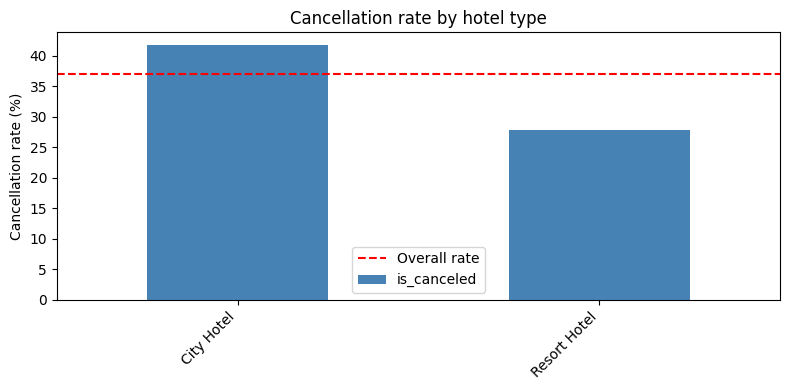

In [149]:
plot_cancel_rate(df, 'hotel', 'Cancellation rate by hotel type')

The City Hotel has a much higher cancellation rate (41.7%) than the Resort Hotel (27.8%). Since the two hotels behave differently, the hotel type is an important feature for the model.

#### Lead time

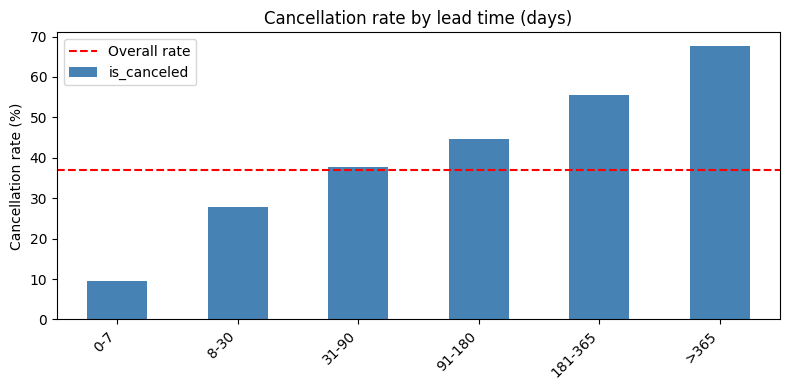

In [150]:
eda = df.copy()
eda['lead_time_group'] = pd.cut(eda['lead_time'],
                                bins=[-1, 7, 30, 90, 180, 365, 1000],
                                labels=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])
plot_cancel_rate(eda, 'lead_time_group', 'Cancellation rate by lead time (days)',
                 order=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])

The cancellation rate grows steadily with the lead time: it is 9.6% for bookings made within one week of arrival and reaches 67.7% for bookings made more than one year in advance (median lead time: 113 days for cancelled bookings vs 45 days for the others). This confirms the hypothesis of the Business Understanding: guests who book far in advance have more time to change their plans. From the hotel's point of view this is partly good news, since many cancellations come from early bookings, which leave time to resell the room.

#### Deposit type

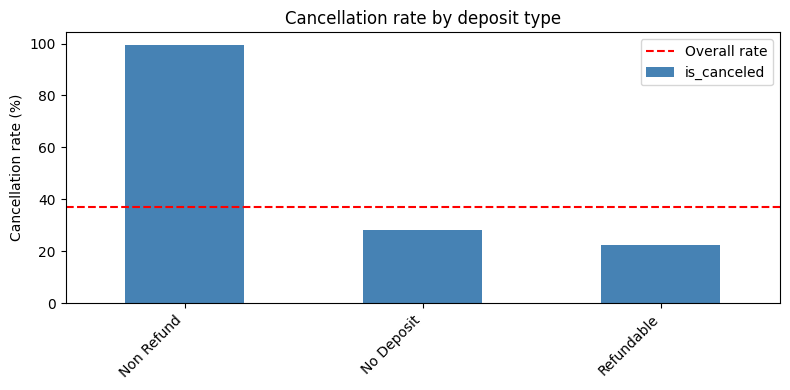

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64


In [151]:
plot_cancel_rate(df, 'deposit_type', 'Cancellation rate by deposit type')
print(df['deposit_type'].value_counts())

In [152]:
non_refund = df[df['deposit_type'] == 'Non Refund']
print(non_refund['hotel'].value_counts(), '\n')
print(non_refund['market_segment'].value_counts().head(), '\n')
print(non_refund['country'].value_counts().head(3))

hotel
City Hotel      12868
Resort Hotel     1719
Name: count, dtype: int64 

market_segment
Groups           9172
Offline TA/TO    5006
Corporate         334
Online TA          56
Direct             19
Name: count, dtype: int64 

country
PRT    14176
GBR      138
ESP      131
Name: count, dtype: int64


This result is counter-intuitive: **99.4% of the Non Refund bookings were cancelled**, while bookings without deposit have a cancellation rate of 28.4%. One would expect a non-refundable deposit to discourage cancellations. Looking at these 14,587 bookings, almost all of them belong to the City Hotel, come from Portugal and from the Groups and Offline TA/TO segments: they are likely block reservations made by tour operators and later released, rather than individual guests losing their money. As a consequence, `deposit_type` will be a very strong predictor, but its effect should not be interpreted as "deposits cause cancellations", and the business recommendations on deposits must take this into account.

#### Market segment and customer history

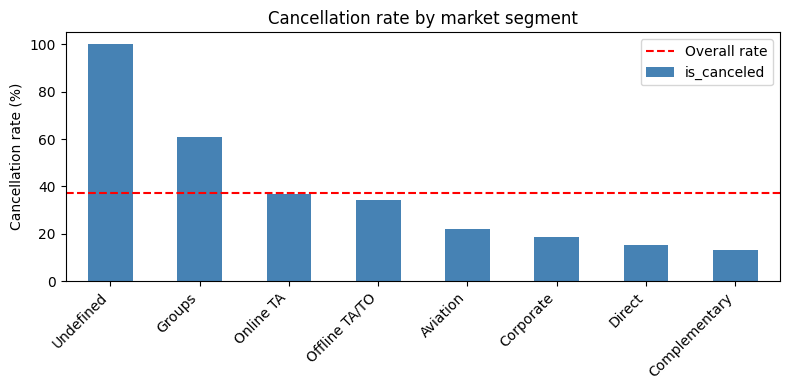

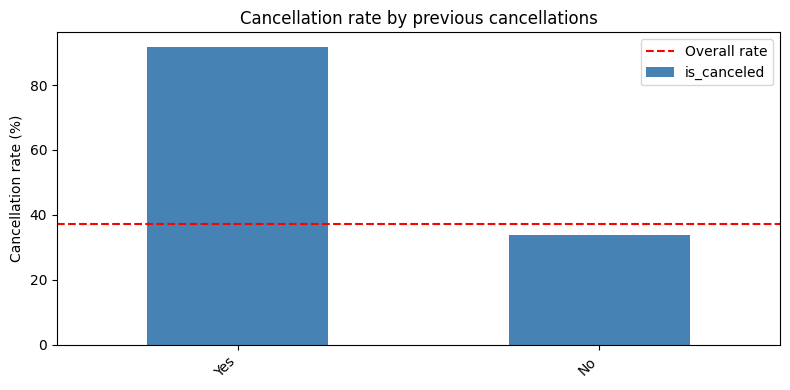

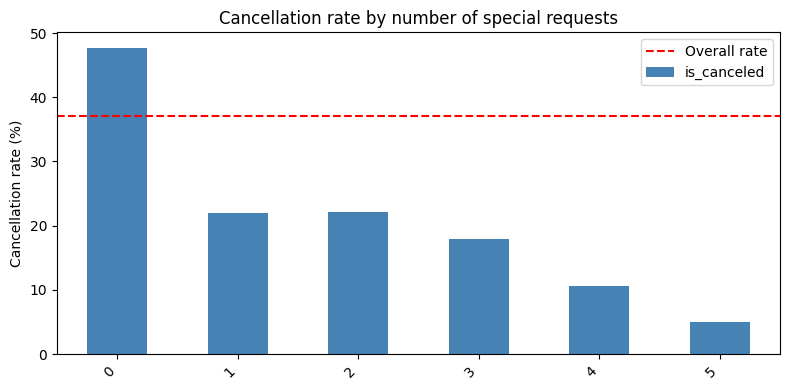

In [153]:
plot_cancel_rate(df, 'market_segment', 'Cancellation rate by market segment')

eda['has_previous_cancellations'] = (eda['previous_cancellations'] > 0).map({True: 'Yes', False: 'No'})
plot_cancel_rate(eda, 'has_previous_cancellations', 'Cancellation rate by previous cancellations')

plot_cancel_rate(df, 'total_of_special_requests', 'Cancellation rate by number of special requests',
                 order=[0, 1, 2, 3, 4, 5])

- **Market segment**: Groups (61.1%) and online travel agencies (36.7%) cancel the most, while Direct (15.3%) and Corporate (18.7%) bookings are much more reliable.
- **Previous cancellations**: guests who already cancelled in the past cancel again in 91.6% of the cases, compared to 33.9% for the others.
- **Special requests**: the more special requests a guest makes, the less likely the booking is cancelled (47.7% with no requests, below 11% with four or more). Special requests are a sign of commitment to the stay.

The `Undefined` category of `market_segment` contains only 2 bookings and is not meaningful.

#### Correlation with the target

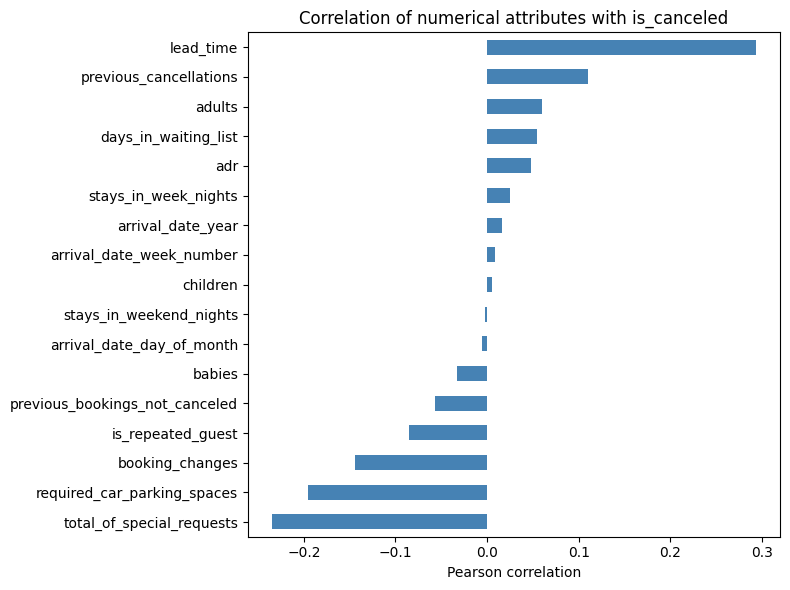

In [154]:
numeric = df.select_dtypes(include='number').drop(columns=['agent', 'company'])
corr = numeric.corr()['is_canceled'].drop('is_canceled').sort_values()

corr.plot(kind='barh', color='steelblue', figsize=(8, 6))
plt.title('Correlation of numerical attributes with is_canceled')
plt.xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

The strongest positive correlation is with `lead_time` (0.29) and `previous_cancellations` (0.11); the strongest negative ones are with `total_of_special_requests` (-0.23), `required_car_parking_spaces` (-0.20) and `booking_changes` (-0.14). All correlations are weak in absolute terms: no single numerical attribute explains cancellations alone, which suggests that a multivariate model is needed. Pearson correlation only captures linear relationships, so it is used here as a first indication.

#### Potential data leakage

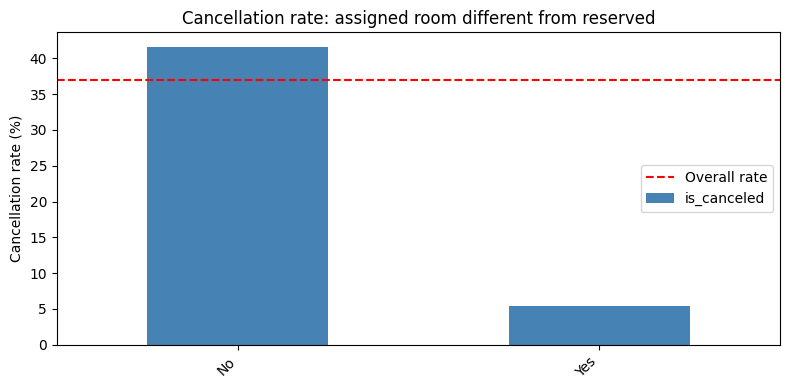

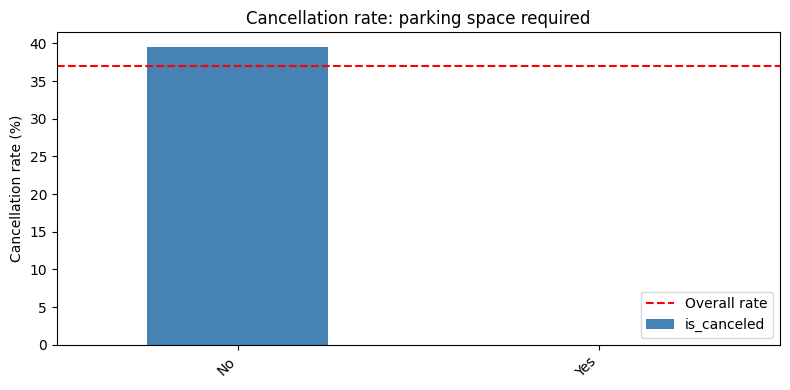

In [155]:
eda['room_changed'] = (eda['reserved_room_type'] != eda['assigned_room_type']).map({True: 'Yes', False: 'No'})
plot_cancel_rate(eda, 'room_changed', 'Cancellation rate: assigned room different from reserved')

eda['parking'] = (eda['required_car_parking_spaces'] > 0).map({True: 'Yes', False: 'No'})
plot_cancel_rate(eda, 'parking', 'Cancellation rate: parking space required')

Two attributes show a suspicious behaviour:
- when the assigned room differs from the reserved one, only 5.4% of bookings are cancelled (vs 41.6%);
- **no booking** with a required parking space was cancelled (0%).

This is not a real behaviour of the guests: the room is assigned and the parking space is registered mostly **at check-in**, so these values are only known for guests who actually arrived. They contain information about the outcome and would not be available at booking time, which is when the model has to make its prediction. They are therefore a form of **data leakage**, like `reservation_status`, and will be handled in Data Preparation.

### 2.5 Data quality

In [156]:
print('Duplicated rows:', df.duplicated().sum())
print('Bookings with no guests:', ((df['adults'] + df['children'].fillna(0) + df['babies']) == 0).sum())
print('Negative adr:', (df['adr'] < 0).sum())
print('adr equal to 0:', (df['adr'] == 0).sum())
print('Max adr:', df['adr'].max())
print('"Undefined" in meal:', (df['meal'] == 'Undefined').sum())
print('"Undefined" in market_segment:', (df['market_segment'] == 'Undefined').sum())
print('"Undefined" in distribution_channel:', (df['distribution_channel'] == 'Undefined').sum())

Duplicated rows: 31994
Bookings with no guests: 180
Negative adr: 1
adr equal to 0: 1959
Max adr: 5400.0
"Undefined" in meal: 1169
"Undefined" in market_segment: 2
"Undefined" in distribution_channel: 5


The data quality checks highlight several issues to address in Data Preparation:
- **31,994 duplicated rows** (27% of the dataset). Since the dataset has no booking identifier, some of them may be different bookings with identical characteristics (e.g. several rooms of the same group); this choice will be discussed.
- **180 bookings with no guests** (adults, children and babies all equal to zero), which are not valid bookings.
- **`adr`** (average daily rate) has one negative value and an extreme maximum of 5,400 €, far above all other values; 1,959 bookings have a rate of 0 (e.g. complementary stays).
- **"Undefined" categories**: 1,169 in `meal` (which, according to the dataset documentation, has the same meaning as `SC`, i.e. no meal package), 2 in `market_segment` and 5 in `distribution_channel`.

## 3. Data Preparation

All preparation steps are applied to a copy of the original dataset (`data`), so that `df` remains available in its original form. Each decision is based on the findings of the Data Understanding phase.

### 3.1 Duplicates and anomalous rows

In [157]:
data = df.copy()
print('Initial shape:', data.shape)

# 1. Duplicated rows
data = data.drop_duplicates()
print('After removing duplicates:', data.shape)
print('Cancellation rate after removing duplicates:', round(data['is_canceled'].mean() * 100, 1), '%')

# 2. Bookings with no guests
total_guests = data['adults'] + data['children'].fillna(0) + data['babies']
data = data[total_guests > 0]

# 3. Negative and extreme adr
data = data[(data['adr'] >= 0) & (data['adr'] < 1000)]

# 4. "Undefined" categories
data = data[(data['market_segment'] != 'Undefined') & (data['distribution_channel'] != 'Undefined')]
data['meal'] = data['meal'].replace('Undefined', 'SC')

print('After removing anomalies:', data.shape)

Initial shape: (119390, 32)
After removing duplicates: (87396, 32)
Cancellation rate after removing duplicates: 27.5 %
After removing anomalies: (87223, 32)


In [158]:
print(data['deposit_type'].value_counts(), '\n')
print((data.groupby('deposit_type')['is_canceled'].mean() * 100).round(1))

deposit_type
No Deposit    86079
Non Refund     1037
Refundable      107
Name: count, dtype: int64 

deposit_type
No Deposit    26.7
Non Refund    94.7
Refundable    24.3
Name: is_canceled, dtype: float64


- **Duplicates**: 31,994 identical rows were removed (from 119,390 to 87,396 bookings). Although some of them could be different bookings with the same characteristics, identical rows add no information to the model and, if kept, the same row could end up both in the training and in the test set, producing an over-optimistic evaluation.
- After this step the cancellation rate drops from 37% to **27.5%**: many duplicates were cancelled bookings. The class imbalance is therefore stronger than it first appeared, which reinforces the choice of Recall, F1-score and PR-AUC.
- The duplicates also explain the Non Refund paradox observed in the exploratory analysis: Non Refund bookings drop from 14,587 to 1,037, confirming that most of them were repeated block reservations (e.g. groups handled by tour operators). Their cancellation rate is still very high (94.7%), so the variable remains strongly predictive.
- **Anomalies**: 180 bookings with no guests, the negative `adr` value and the extreme value of 5,400 € were removed, together with the 7 rows with "Undefined" market segment or distribution channel. "Undefined" in `meal` was replaced with `SC`, which has the same meaning (no meal package). The final dataset contains **87,223 bookings**.

### 3.2 Missing values

In [159]:
# children: only 4 missing values -> 0, then integer
data['children'] = data['children'].fillna(0).astype(int)

# country: missing -> 'Unknown'; keep the 10 most frequent countries, group the others
data['country'] = data['country'].fillna('Unknown')
top_countries = data['country'].value_counts().head(10).index
data['country'] = data['country'].where(data['country'].isin(top_countries), 'Other')

# agent: identifier -> category; keep the 10 most frequent agents
top_agents = data['agent'].value_counts().head(10).index
data['agent'] = np.where(data['agent'].isna(), 'No agent',
                np.where(data['agent'].isin(top_agents), data['agent'].astype('Int64').astype(str), 'Other'))

# company: 94% missing -> replaced by a binary flag
data['has_company'] = data['company'].notna().astype(int)
data = data.drop(columns=['company'])

print('Remaining missing values:', data.isnull().sum().sum())

Remaining missing values: 0


- **children** (4 missing): replaced with 0, the most plausible value, and converted to integer.
- **country** (0.4% missing): replaced with the category "Unknown". Since `country` has 178 different values, only the 10 most frequent countries are kept and the others are grouped into "Other", to avoid creating hundreds of sparse columns during encoding.
- **agent** (14% missing): a missing value means that the booking was **not made through an agency**, so it is informative and becomes the category "No agent". As `agent` is an identifier with 333 different values, only the 10 most frequent agents are kept and the others are grouped into "Other".
- **company** (94% missing): too empty to be used as it is. It is replaced by a binary feature `has_company` (1 if the booking was made by a company), since company bookings cancel much less (10.9% vs 28.6%).

### 3.3 Leakage removal

In [160]:
leakage_cols = ['reservation_status', 'reservation_status_date',
                'assigned_room_type', 'required_car_parking_spaces']
date_cols = ['arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month']

data = data.drop(columns=leakage_cols + date_cols)
print('Shape after removing leakage and date columns:', data.shape)

Shape after removing leakage and date columns: (87223, 25)


The model must predict cancellations **at booking time**, so it can only use information available at that moment.
- `reservation_status` and `reservation_status_date` directly describe the outcome of the booking (e.g. "Canceled").
- `assigned_room_type` and `required_car_parking_spaces` are mostly recorded at check-in, so they are known only for guests who actually arrived (see the exploratory analysis). For this reason, the feature initially planned in the proposal ("consistency between reserved and assigned room") was **not** created: it would contain information about the outcome.

Three date attributes were also removed: `arrival_date_year`, because the model should work on future years that are not in the data, and `arrival_date_week_number` and `arrival_date_day_of_month`, because seasonality is already captured by `arrival_date_month`.

`booking_changes` was kept, but it is a possible limitation: changes can be made until the arrival date, so at booking time this value may not be final.

### 3.4 Feature engineering

In [161]:
data['total_nights'] = data['stays_in_weekend_nights'] + data['stays_in_week_nights']
data['total_guests'] = data['adults'] + data['children'] + data['babies']
data['has_children'] = ((data['children'] + data['babies']) > 0).astype(int)
data['has_previous_cancellations'] = (data['previous_cancellations'] > 0).astype(int)

print('Shape after feature engineering:', data.shape)

Shape after feature engineering: (87223, 29)


Four new features were created from existing attributes:
- `total_nights`: length of the stay (weekend + week nights);
- `total_guests`: number of people in the booking;
- `has_children`: whether the booking includes children or babies (families may plan differently from other travellers);
- `has_previous_cancellations`: whether the guest has cancelled before, since the exploratory analysis showed a cancellation rate above 90% for these guests.

### 3.5 Encoding and train/test split

In [162]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['is_canceled'])
y = data['is_canceled']

categorical_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Categorical columns:', categorical_cols)

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)
print('Shape after encoding:', X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('Train:', X_train.shape, '- Test:', X_test.shape)
print('Cancellation rate - train:', round(y_train.mean() * 100, 1), '% - test:', round(y_test.mean() * 100, 1), '%')

Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']
Shape after encoding: (87223, 76)
Train: (69778, 76) - Test: (17445, 76)
Cancellation rate - train: 27.5 % - test: 27.5 %


Categorical attributes were transformed with **one-hot encoding**, since the models require numerical inputs and the categories have no natural order; one column per variable is dropped (`drop_first=True`) to avoid redundancy. The final dataset has 76 features.

The data were split into a training set (80%, 69,778 bookings) and a test set (20%, 17,445 bookings). The split is **stratified**, so both sets keep the same cancellation rate (27.5%), and a fixed `random_state` makes the results reproducible. The test set is used only for the final evaluation.

A random split was chosen for simplicity; a **time-based split** (training on older bookings and testing on the most recent ones) would be even closer to the real use of the model and is discussed as possible future work.

## 4. Modeling

### 4.1 Modeling strategy
Four classification models of increasing complexity are compared:
- **Logistic Regression**: a linear model, used as a simple and interpretable reference;
- **Decision Tree**: a non-linear model that can be read as a set of rules;
- **Random Forest**: an ensemble of decision trees trained in parallel on random subsets of data and features (*bagging*);
- **XGBoost**: an ensemble of trees trained in sequence, where each tree corrects the errors of the previous ones (*boosting*).

A **majority-class baseline** (always predicting "not cancelled") is also included, to show the minimum level that any useful model must exceed.

**Class imbalance** (27.5% cancellations) is handled by giving more weight to the minority class during training (`class_weight='balanced'`, and `scale_pos_weight` for XGBoost), instead of creating synthetic samples, so the training data remain real bookings.

**Hyperparameters** are tuned on the training set only, with **stratified cross-validation** (5 folds; 3 folds for the two ensembles, to limit computation time). The best configuration of each model is selected according to **PR-AUC**, consistently with the metrics chosen in the Business Understanding phase. The test set is not used in this phase.

In [163]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, precision_score
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'precision': make_scorer(precision_score, zero_division=0),
           'recall': 'recall', 'f1': 'f1', 'pr_auc': 'average_precision'}
results = {}

def summarize(name, search):
    i = search.best_index_
    r = search.cv_results_
    results[name] = {m: round(float(r[f'mean_test_{m}'][i]), 3) for m in scoring}
    print(name, '- best parameters:', search.best_params_)
    print(results[name])

### 4.2 Baseline

In [164]:
dummy = cross_validate(DummyClassifier(strategy='most_frequent'), X_train, y_train, cv=cv, scoring=scoring)
results['Baseline (majority class)'] = {m: round(float(dummy[f'test_{m}'].mean()), 3) for m in scoring}
print(results['Baseline (majority class)'])

{'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'pr_auc': 0.275}


The baseline never predicts a cancellation, so Precision, Recall and F1 are all 0. Its PR-AUC (0.275) is equal to the share of cancelled bookings: this is the value of a model with no predictive ability, and the reference that the other models must exceed.

### 4.3 Logistic Regression
Features are standardised (mean 0, standard deviation 1) because Logistic Regression is sensitive to the scale of the variables. The scaler is included in a `Pipeline`, so that it is fitted only on the training folds during cross-validation. The tuned hyperparameter `C` controls the strength of regularisation (smaller values = simpler model).

In [165]:
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=2000))
])
lr_search = GridSearchCV(lr_pipe, {'model__C': [0.01, 0.1, 1, 10]},
                         cv=cv, scoring=scoring, refit='pr_auc', n_jobs=-1)
lr_search.fit(X_train, y_train)
summarize('Logistic Regression', lr_search)

Logistic Regression - best parameters: {'model__C': 0.01}
{'precision': 0.527, 'recall': 0.769, 'f1': 0.625, 'pr_auc': 0.643}


### 4.4 Decision Tree
Trees do not require scaling. The tuned hyperparameters limit the growth of the tree to avoid overfitting: `max_depth` (maximum depth) and `min_samples_leaf` (minimum number of bookings in each leaf).

In [166]:
dt_search = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                         {'max_depth': [5, 10, 15, 20, None], 'min_samples_leaf': [1, 10, 50]},
                         cv=cv, scoring=scoring, refit='pr_auc', n_jobs=-1)
dt_search.fit(X_train, y_train)
summarize('Decision Tree', dt_search)

Decision Tree - best parameters: {'max_depth': 20, 'min_samples_leaf': 50}
{'precision': 0.551, 'recall': 0.803, 'f1': 0.654, 'pr_auc': 0.698}


### 4.5 Random Forest
A random search over 6 combinations is used instead of a full grid search, to keep the computation time reasonable. The tuned hyperparameters are the depth of the trees, the minimum leaf size and the number of features considered at each split (`max_features`).

In [167]:
rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
    {'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5, 10], 'max_features': ['sqrt', 0.3]},
    n_iter=6, cv=3, scoring=scoring, refit='pr_auc', random_state=42)
rf_search.fit(X_train, y_train)
summarize('Random Forest', rf_search)

Random Forest - best parameters: {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': None}
{'precision': 0.618, 'recall': 0.782, 'f1': 0.69, 'pr_auc': 0.748}


### 4.6 XGBoost
`scale_pos_weight` is set to the ratio between non-cancelled and cancelled bookings, to give more weight to the minority class. The tuned hyperparameters are the number of trees, their depth, the learning rate and the share of rows and columns used by each tree.

In [168]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=ratio, eval_metric='logloss', random_state=42, n_jobs=-1),
    {'n_estimators': [200, 400], 'max_depth': [4, 6, 8], 'learning_rate': [0.05, 0.1],
     'subsample': [0.8, 1.0], 'colsample_bytree': [0.8, 1.0]},
    n_iter=8, cv=3, scoring=scoring, refit='pr_auc', random_state=42)
xgb_search.fit(X_train, y_train)
summarize('XGBoost', xgb_search)

XGBoost - best parameters: {'subsample': 1.0, 'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
{'precision': 0.606, 'recall': 0.812, 'f1': 0.694, 'pr_auc': 0.763}


### 4.7 Cross-validation results

In [169]:
cv_results = pd.DataFrame(results).T
cv_results

,precision,recall,f1,pr_auc
Baseline (majority class),0.000,0.000,0.000,0.275
Logistic Regression,0.527,0.769,0.625,0.643
Decision Tree,0.551,0.803,0.654,0.698
Random Forest,0.618,0.782,0.690,0.748
XGBoost,0.606,0.812,0.694,0.763


| Model | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|
| Baseline | 0.000 | 0.000 | 0.000 | 0.275 |
| Logistic Regression | 0.527 | 0.769 | 0.625 | 0.643 |
| Decision Tree | 0.551 | 0.803 | 0.654 | 0.698 |
| Random Forest | 0.618 | 0.782 | 0.690 | 0.748 |
| XGBoost | 0.606 | 0.812 | 0.694 | 0.763 |

All models clearly outperform the baseline. Performance increases with model complexity: the linear Logistic Regression is the weakest, which suggests that the relationships between features and cancellations are not linear; the two ensembles are the best, with **XGBoost** obtaining the highest PR-AUC (0.763) and F1-score (0.694), closely followed by Random Forest.

Thanks to class weighting, all models reach a Recall around 0.77–0.81: they identify about 4 cancellations out of 5, at the cost of a lower Precision (about 4 alarms out of 10 are false), which is acceptable given the low cost of false positives in the chosen business scenario.

These results are lower than those often reported for this dataset because duplicates and leakage variables (e.g. `reservation_status`, `assigned_room_type`) were removed: the performance obtained here is more realistic for a model used at booking time.

## 5. Evaluation

## 6. Deployment